# Step 5 – Baselines

Plan reference: `schneider_problem1_plan.md`, Step 5. Write-up: `report/problem1/step5_baseline.md`. The logic is in `src/`:

| Module | Role |
|---|---|
| `src/baselines.py` | the five baselines, the rolling-origin backtest and the metrics |
| `src/baseline_plots.py` | charts (saved in `plots/step5/`) |

The baselines reuse the Step 4 feature tables (`Data/processed/features/`) and the Step 4 selected features
(`report/problem1/step4_tables/selected_features.csv`).

Run order from a clean clone: `src.data_prep` → `src.external_data` → `src.features` → this notebook
(or `src.baselines` then `src.baseline_plots`).

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
# The pipeline uses paths relative to the repo root (Data/, configs/).
if Path.cwd().name == "analysis":
    os.chdir("..")
import numpy as np
import pandas as pd
from IPython.display import display

from src import baselines as B, baseline_plots as BP
from src.feature_plots import TARGET_NAMES
from src.features import load_config

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
BP.set_style()

cfg = load_config()
H = cfg["settings"]["horizons"]
QS = cfg["selection"]["quantiles"]
GROUP = {t: "market" for t in ["S01", "D01", "S02", "D02", "S03", "S04", "S05"]} | {"EPOXY_EUR": "epoxy"}
group_of = lambda t: GROUP.get(t, "ppi")
print("horizons:", H, "| quantiles:", QS, "| selection window ends:", cfg["selection"]["select_end"])

horizons: [3, 6, 9] | quantiles: [0.1, 0.5, 0.9] | selection window ends: 2025-03


## 1. Inputs

**Target.** For a price *P*, origin month *o* and horizon *H*: `y = log(P[o+H]) − log(P[o])`, roughly the % change
over the next H months. Same target, timing and leakage rules as Step 4.

**Step 4 selected features.** The `features_qr` baseline uses them. Where Step 4 kept none (28 of 45 cells),
`features_qr` is identical to the historical quantiles.

In [2]:
selected = B.load_selected()
sel = pd.DataFrame([{"target": t, "name": TARGET_NAMES[t], "horizon": h, "features": ", ".join(f) or "–"}
                    for (t, h), f in selected.items()])
display(sel.pivot(index=["target", "name"], columns="horizon", values="features").reindex(BP.TARGET_ORDER, level=0))
print("cells with at least one feature:", sum(bool(f) for f in selected.values()), "of", len(selected))

,horizon,3,6,9
target,name,,,
S01,Copper USD,–,–,–
D01,Copper EUR,own_pos_12m_range,–,–
S02,Aluminium USD,–,–,–
D02,Aluminium EUR,–,–,own_chg_1m
S03,Nickel,"own_chg_3m, own_chg_1m",–,–
S04,Iron ore,–,own_chg_3m,–
S05,Zinc,–,own_chg_3m,–
S07,EU copper PPI,–,–,–
S08,EU alu. PPI,"own_chg_1m, d02_chg_1m",own_chg_1m,d02_chg_1m


cells with at least one feature: 17 of 45


## 2. The baselines

All give a **P10 / P50 / P90** of `y` (the submission format).

| Baseline | P50 | P10 / P90 band |
|---|---|---|
| `random_walk` | 0: the price stays where it is | spread of past H-month changes around their median, centred on 0 |
| `drift` | mean of past H-month changes | same spread, centred on the drift |
| `hist_quantiles` | median of past H-month changes | 10th / 90th percentiles of past H-month changes |
| `lme_forward` | log(LME 3-month ÷ cash) at the origin | forward + percentiles of past forward errors (Cu / Al, 3 months only) |
| `features_qr` | linear quantile regression on the Step 4 features | same regression at P10 and P90 |

**Backtest.** Rolling origin, expanding window, refitted every month. At each test origin *T*, a model is trained only
on origins whose outcome was known at *T* (*o + H ≤ T*). First test origin: 48 months after the first row (Nov 2021).
All models of a target × horizon are scored on the same origins.

| Window | Target months | Comment |
|---|---|---|
| backtest | Feb 2022 → Mar 2025 | Step 4 chose its features here: `features_qr` looks better than it is |
| hold-out | Apr 2025 → Sep 2026 | never used by Step 4: clean |

Running every baseline on every target and horizon takes about 1.5 minutes.

In [3]:
out = B.run()
pred, metrics, live = out["predictions"], out["metrics"], out["live"]

# Same files as `uv run python -m src.baselines`
B.PRED_DIR.mkdir(parents=True, exist_ok=True)
B.TABLE_DIR.mkdir(parents=True, exist_ok=True)
pred.to_csv(B.PRED_DIR / "predictions.csv", index=False)
metrics.round(4).to_csv(B.TABLE_DIR / "metrics.csv", index=False)
live.to_csv(B.TABLE_DIR / "live_forecast_202609.csv", index=False)

metrics["group"] = metrics["target"].map(group_of)
print(f"{len(pred):,} forecasts | {pred['target'].nunique()} targets | models: {sorted(pred['model'].unique())}")
display(metrics.groupby(["window", "horizon"])["n"].agg(["min", "max"]).rename(columns={"min": "test origins (min)", "max": "test origins (max)"}))

9,780 forecasts | 15 targets | models: ['drift', 'features_qr', 'hist_quantiles', 'lme_forward', 'random_walk']


test origins (min)  test origins (max)
window   horizon                                        
backtest 3                        24                  38
         6                        21                  35
         9                        18                  32
holdout  3                        18                  18
         6                        18                  18
         9                        18                  18

### Example: one forecast

EU steel PPI (S09), 3 months, from the origin December 2024. Every model's P10 / P50 / P90 in % change,
and what actually happened.

In [4]:
ex = pred[(pred["target"] == "S09") & (pred["horizon"] == 3) & (pred["origin"] == "2024-12-01")]
display((ex.set_index("model")[["p10", "p50", "p90", "y"]] * 100).round(2).assign(n_train=ex.set_index("model")["n_train"]))

,p10,p50,p90,y,n_train
model,,,,,
random_walk,-4.65,0.00,14.70,-0.1,83
drift,-3.72,0.93,15.63,-0.1,83
hist_quantiles,-5.78,-1.13,13.57,-0.1,83
features_qr,-4.72,-0.51,5.91,-0.1,83


**How to read the scores.**
- **Pinball loss** averaged over P10, P50 and P90 (in % log change): the main score. Lower is better.
- **Skill vs random walk** = 1 − loss ÷ random-walk loss. Positive = better than the random walk.
- **Coverage**: share of outcomes inside P10–P90. Should be **80 %**.
- H-month windows overlap, so 36 test origins at 9 months hold only about 4 independent outcomes. **Differences
  below about 10 % are within the noise.**

## 3. Results

### 3.1 Skill vs random walk, by type of material

Average over targets. *market* = LME copper, aluminium, nickel, zinc, iron ore; *ppi* = EU and US producer price
indices; *epoxy* on its own.

In [5]:
skill = (metrics[metrics["model"] != "random_walk"]
         .pivot_table(index=["window", "group"], columns=["horizon", "model"], values="pinball_skill_vs_rw"))
display((100 * skill).round(0).style.format("{:+.0f} %", na_rep="–")
        .background_gradient(cmap="RdBu", vmin=-30, vmax=30, axis=None))

- **The random walk is the one to beat.** In the backtest, no baseline without features beats it on average.
- **`features_qr` beats it at 3 months for the price indices**, in the backtest and in the hold-out.
- **Drift is the worst**, especially for the price indices at 6–9 months: it extrapolated the 2017–2021 rise.
- Hold-out gains for market prices come from the 2025–26 copper rally (section 3.3), not from skill.

### 3.2 Where the features help

In [6]:
fq = metrics[(metrics["model"] == "features_qr") & (metrics["horizon"] == 3)]
fq = fq[fq.apply(lambda r: bool(selected[(r["target"], 3)]), axis=1)]
tab = fq.pivot(index="target", columns="window", values="pinball_skill_vs_rw").mul(100).round(0)
tab.insert(0, "features", [", ".join(selected[(t, 3)]) for t in tab.index])
tab.index = [TARGET_NAMES[t] for t in tab.index]
display(tab.sort_values("holdout", ascending=False))

window,features,backtest,holdout
EU steel PPI,own_chg_1m,18.0,38.0
DE steel PPI,own_chg_1m,20.0,34.0
EU alu. PPI,"own_chg_1m, d02_chg_1m",27.0,31.0
Copper EUR,own_pos_12m_range,1.0,8.0
US steel PPI,iron_ore_usd_chg_3m,13.0,-2.0
EU plastics PPI,"own_chg_3m, brent_eur_chg_1m",16.0,-8.0
Nickel,"own_chg_3m, own_chg_1m",4.0,-14.0


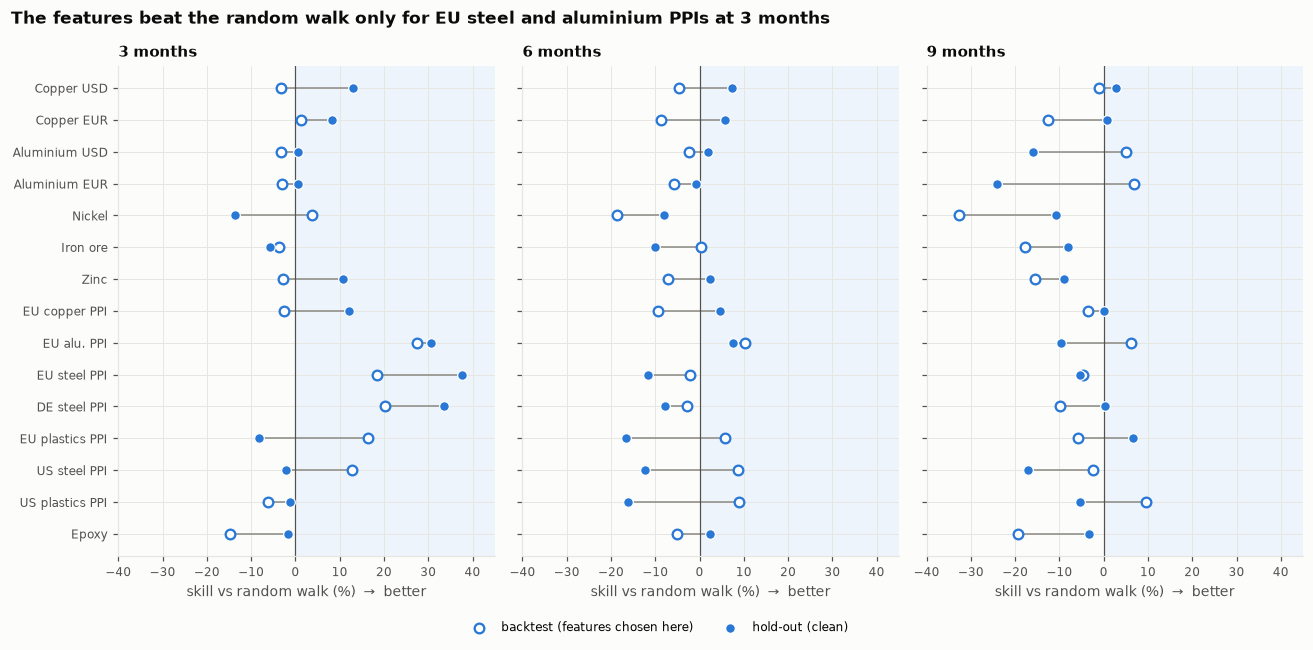

In [7]:
BP.feature_skill(metrics);

*Open circle = backtest (features chosen here), filled dot = hold-out (clean). Right of the line = better than the
random walk.* Only the **EU aluminium and steel PPIs at 3 months** are clearly better on both windows. These drive
AirSeT's raw-material cost. Plastics, US steel and nickel lose their gain out of sample.

**For Step 6:** keep the 3-month features for the steel and aluminium PPIs. Elsewhere the median is essentially a
random walk, so the effort should go into the band (section 3.4).

### 3.3 Drift and the LME forward

Bias = average of (outcome − median forecast), in %. Positive = the model forecast too low.

In [8]:
bias = metrics[metrics["model"].isin(["random_walk", "drift", "lme_forward"])].pivot_table(
    index=["window", "group"], columns=["horizon", "model"], values="bias")
display(bias.round(1))

fwd = metrics[metrics["model"] == "lme_forward"][["target", "window", "pinball_skill_vs_rw", "coverage_80"]]
fwd = fwd.assign(target=fwd["target"].map(TARGET_NAMES)).set_index(["target", "window"]).unstack("window")
display(fwd.round(2))

horizon             3                             6                 9            
model           drift lme_forward random_walk drift random_walk drift random_walk
window   group                                                                   
backtest epoxy   -3.0         NaN        -1.7  -5.8        -2.8  -8.0        -2.9
         market  -2.0        -1.4        -0.6  -5.9        -2.9  -9.5        -4.6
         ppi     -2.8         NaN        -1.0  -6.5        -2.7 -11.1        -5.0
holdout  epoxy    0.7         NaN         1.4   1.2         2.7  -0.7         1.9
         market   2.3         3.9         3.3   5.2         6.9   7.6        10.1
         ppi      1.3         NaN         2.3   2.4         4.3   1.8         4.8

pinball_skill_vs_rw         coverage_80        
window                   backtest holdout    backtest holdout
target                                                       
Aluminium EUR               -0.02    0.05        0.71    0.67
Aluminium USD               -0.02    0.03        0.79    0.67
Copper EUR                  -0.03    0.11        0.82    0.83
Copper USD                  -0.05    0.14        0.82    0.83

- **Drift:** in the backtest it forecast rises while prices fell, which is the source of its large losses. In the
  hold-out it looks fine only because copper and aluminium then rose.
- **LME forward:** the 3-month premium over cash is small, so it is close to a random walk: slightly worse in the
  backtest, slightly better in the hold-out (copper rally). Not a reliable improvement, but worth reporting as the
  market's own forecast.

### 3.4 Calibration: the bands are wrong in both directions

Coverage of the 80 % band, random walk, average over targets:

In [9]:
cov = metrics[metrics["model"] == "random_walk"].pivot_table(index="group", columns=["window", "horizon"], values="coverage_80")
display((100 * cov).round(0).style.format("{:.0f} %").background_gradient(cmap="RdBu", vmin=50, vmax=110, axis=None))

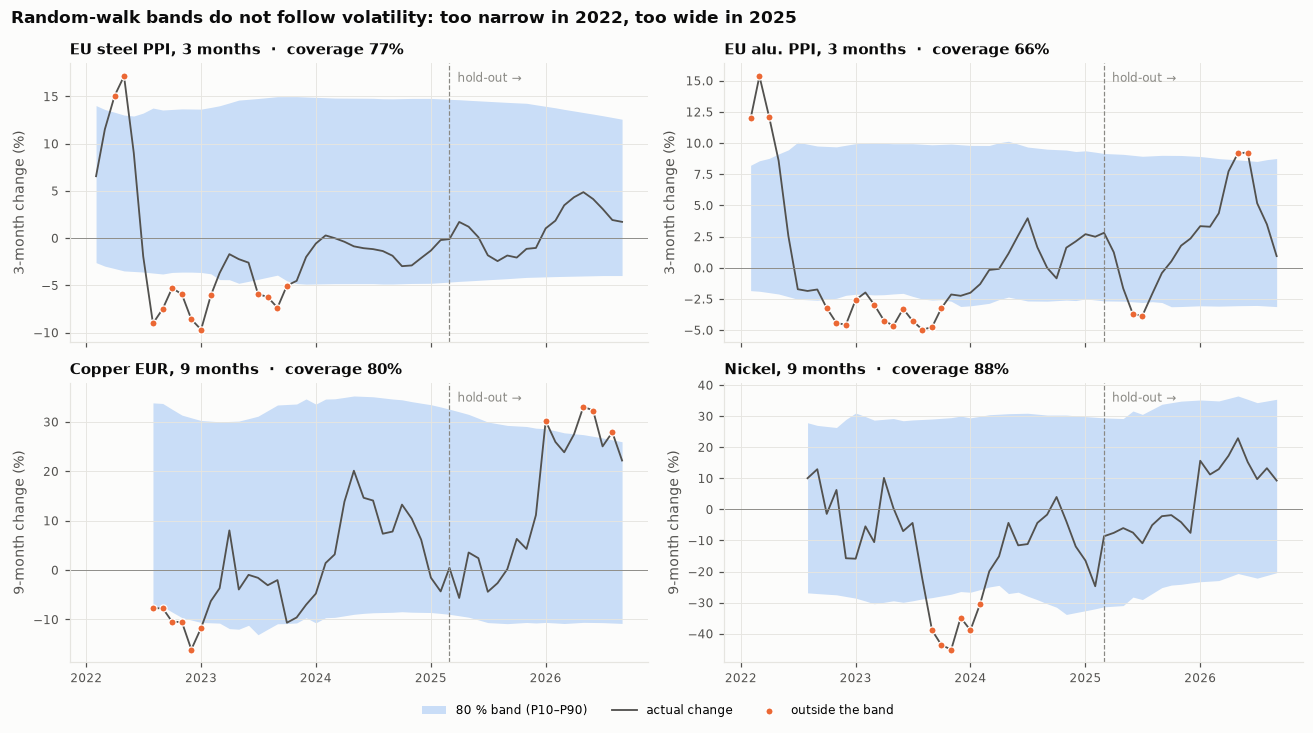

In [10]:
BP.bands_vs_outcomes(pred, [("S09", 3), ("S08", 3), ("D01", 9), ("S03", 9)]);

*Blue = random-walk 80 % band, line = actual change, orange = outcome outside the band.* The band barely moves over
four years, while volatility changes a lot: too narrow for the price indices in 2022–23, much too wide in 2025–26.
Copper's 2026 rally and nickel's 2023 fall break through it.

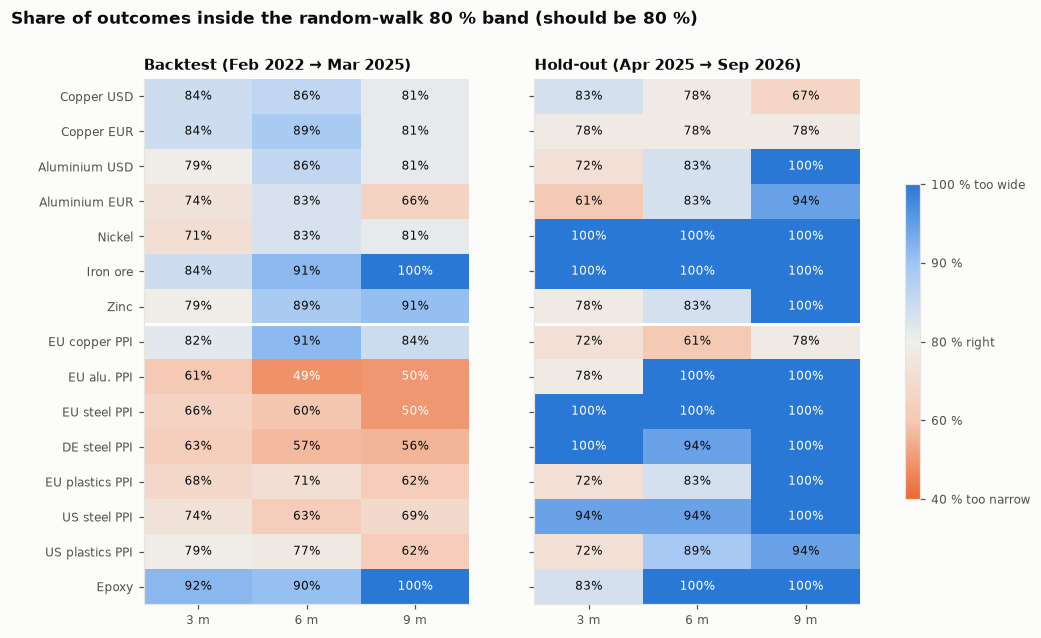

In [11]:
BP.coverage_heatmap(metrics);

*Orange = band too narrow (buffer too small), blue = band too wide (buffer costs competitiveness).* The price indices go
from orange in the backtest to blue in the hold-out. **A good Step 6 model should turn both panels pale grey.**

Band width also shows the problem: the random-walk band hardly changes between the two windows, although the
2022 shock and the calm of 2025 are very different markets.

In [12]:
w = metrics[metrics["model"] == "random_walk"].pivot_table(index="group", columns=["window", "horizon"], values="width_80")
display(w.round(1))

window  backtest             holdout            
horizon        3     6     9       3     6     9
group                                           
epoxy       15.5  28.7  38.2    14.4  28.0  36.8
market      30.3  44.9  56.2    28.8  41.5  52.8
ppi         16.5  29.6  41.8    15.4  26.5  39.3

### 3.5 Baseline forecasts at the September 2026 origin

Price index, September 2026 = 100.

In [13]:
lv = live[live["model"].isin(["random_walk", "features_qr", "lme_forward"])].copy()
lv["name"] = lv["target"].map(TARGET_NAMES)
lv["P10 / P50 / P90"] = lv.apply(lambda r: f"{r.index_p10:.1f} / {r.index_p50:.1f} / {r.index_p90:.1f}", axis=1)
display(lv.pivot_table(index=["target", "name", "horizon"], columns="model", values="P10 / P50 / P90", aggfunc="first")
        .reindex(BP.TARGET_ORDER, level=0))

model                                       features_qr           lme_forward           random_walk
target    name            horizon                                                                  
S01       Copper USD      3        91.6 / 101.9 / 116.8  91.4 / 101.3 / 116.3  89.9 / 100.0 / 114.6
                          6        89.4 / 103.5 / 125.4                   NaN  86.4 / 100.0 / 121.1
                          9        88.1 / 103.6 / 137.0                   NaN  85.1 / 100.0 / 132.2
D01       Copper EUR      3        87.2 / 102.6 / 117.3  91.5 / 101.8 / 113.4  90.4 / 100.0 / 112.5
                          6        91.2 / 103.1 / 123.8                   NaN  88.5 / 100.0 / 120.0
                          9        90.6 / 103.0 / 135.6                   NaN  88.0 / 100.0 / 131.7
S02       Aluminium USD   3        90.7 / 101.4 / 115.3   90.3 / 99.4 / 113.9  89.4 / 100.0 / 113.6
                          6        88.4 / 101.7 / 125.2                   NaN  86.9 / 100.0 / 123.1
                          9        84.1 / 100.7 / 138.0                   NaN  83.5 / 100.0 / 137.0
D02       Aluminium EUR   3        90.3 / 101.2 / 114.8  90.7 / 100.1 / 113.1  89.2 / 100.0 / 113.5
                          6        87.6 / 101.6 / 125.7                   NaN  86.3 / 100.0 / 123.8
                          9         85.8 / 98.8 / 135.9                   NaN  87.8 / 100.0 / 138.9
S03       Nickel          3        85.1 / 101.0 / 118.9                   NaN  83.4 / 100.0 / 118.6
                          6         76.9 / 99.8 / 129.3                   NaN  77.1 / 100.0 / 129.6
                          9         79.6 / 98.9 / 135.6                   NaN  80.5 / 100.0 / 137.2
S04       Iron ore        3        83.5 / 101.5 / 126.2                   NaN  82.3 / 100.0 / 124.4
                          6        79.7 / 101.6 / 138.7                   NaN  77.5 / 100.0 / 136.7
                          9         73.3 / 99.6 / 152.4                   NaN  73.6 / 100.0 / 153.0
S05       Zinc            3        83.9 / 102.8 / 113.8                   NaN  81.6 / 100.0 / 110.7
                          6        74.4 / 106.4 / 116.7                   NaN  79.2 / 100.0 / 117.4
                          9        77.8 / 103.1 / 126.6                   NaN  75.4 / 100.0 / 122.8
S07       EU copper PPI   3        95.0 / 101.9 / 109.0                   NaN  93.3 / 100.0 / 107.0
                          6        94.5 / 102.2 / 117.1                   NaN  92.5 / 100.0 / 114.6
                          9        95.6 / 101.0 / 125.0                   NaN  94.7 / 100.0 / 123.8
S08       EU alu. PPI     3        97.4 / 100.2 / 102.5                   NaN  96.9 / 100.0 / 109.0
                          6         94.0 / 99.2 / 106.5                   NaN  93.1 / 100.0 / 116.8
                          9        92.8 / 100.7 / 121.7                   NaN  91.1 / 100.0 / 124.5
S09       EU steel PPI    3        97.0 / 100.3 / 105.5                   NaN  96.2 / 100.0 / 112.8
                          6         91.9 / 98.3 / 122.8                   NaN  93.4 / 100.0 / 124.9
                          9         88.0 / 97.8 / 132.2                   NaN  90.1 / 100.0 / 135.2
S10       DE steel PPI    3        96.7 / 101.3 / 107.3                   NaN  97.3 / 100.0 / 113.7
                          6         92.7 / 97.5 / 122.4                   NaN  95.0 / 100.0 / 125.5
                          9         89.6 / 96.4 / 132.0                   NaN  93.0 / 100.0 / 136.9
S11       EU plastics PPI 3        99.7 / 100.2 / 103.5                   NaN  96.1 / 100.0 / 108.5
                          6         92.8 / 98.0 / 108.6                   NaN  93.4 / 100.0 / 118.1
                          9        94.3 / 100.9 / 128.8                   NaN  92.2 / 100.0 / 125.0
S12       US steel PPI    3         90.8 / 99.8 / 116.0                   NaN  91.5 / 100.0 / 114.9
                          6         88.8 / 97.9 / 128.8                   NaN  90.7 / 100.0 / 131.6


## 4. What Steps 6 and 7 should beat

| Target group | Horizon | Baseline to beat |
|---|---|---|
| EU aluminium and steel PPIs (S08, S09, S10) | 3 m | `features_qr` |
| All other targets and horizons | 3 / 6 / 9 m | `random_walk` |
| Copper and aluminium | 3 m | also report `lme_forward` |

On **pinball loss and 80 % coverage**, on both windows. The hold-out numbers here come from fixed rules (nothing was
tuned on them); Step 6 should not use them to choose models.

**Improvements to try first** (details in `report/problem1/step5_baseline.md`, section 5):
1. Volatility-scaled bands (EWMA / GARCH × √H) around the random-walk median.
2. Conformal calibration of the band on recent coverage errors.
3. Feature median for the steel and aluminium PPIs at 3 months, with a volatility-scaled band.
4. Longer history for the bands (back to the 1990s, including 2008–09).
5. Re-select features inside each backtest fold; test differences with a block bootstrap.